In [1]:
# Cell 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

print("All libraries loaded!")

All libraries loaded!


In [2]:
# Cell 2: Load the same dataset used in Tasks 1, 2, and 3
df = pd.read_csv('/mnt/software_requirements_cleaned.csv')

print("Shape:", df.shape)
print(df.head())
print("\nValue counts of Type_encoded:")
print(df['Type_encoded'].value_counts())

Shape: (527, 5)
  Type                                        Description  Type_encoded  \
0   PE  The system shall refresh the display every 60 ...             7   
1   LF  The application shall match the color of the s...             4   
2   US  If projected  the data must be readable.  On a...            11   
3    A  The product shall be available during normal b...             0   
4   US  If projected  the data must be understandable....            11   

   requirement_length  requirement_length_scaled  
0                  54                  -1.033178  
1                  96                  -0.338042  
2                 159                   0.704661  
3                 196                   1.317043  
4                 203                   1.432898  

Value counts of Type_encoded:
Type_encoded
1     198
11     61
6      55
10     54
7      52
4      32
0      20
9      20
5      14
3      10
2       9
8       2
Name: count, dtype: int64


In [3]:
# Cell 3: Create binary target
df['is_functional'] = (df['Type_encoded'] == 1).astype(int)

print("Binary class distribution:")
print(df['is_functional'].value_counts())
print("\n0 = Non-Functional,  1 = Functional requirement")

Binary class distribution:
is_functional
0    329
1    198
Name: count, dtype: int64

0 = Non-Functional,  1 = Functional requirement


In [4]:
# Cell 4: Features and target
X = df[['requirement_length', 'requirement_length_scaled']]
y = df['is_functional']

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Train size: {X_train_scaled.shape}")
print(f"Test size : {X_test_scaled.shape}")

Train size: (421, 2)
Test size : (106, 2)


In [5]:
# Cell 5: Train the model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Training Accuracy:", round(model.score(X_train_scaled, y_train), 4))
print("Test Accuracy    :", round(model.score(X_test_scaled, y_test), 4))

Training Accuracy: 0.6128
Test Accuracy    : 0.6509


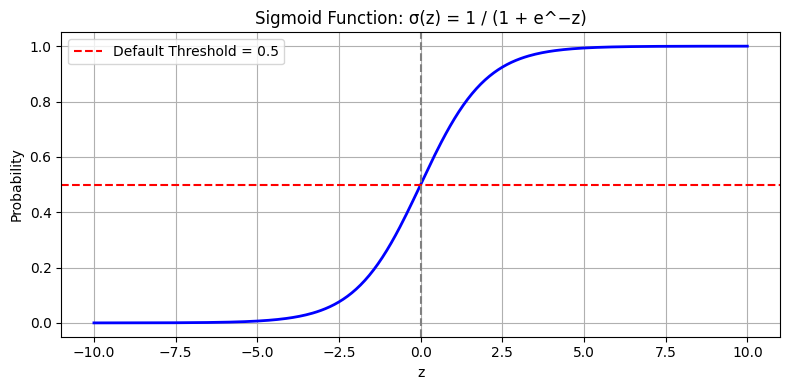

In [6]:
# Cell 6: Visualize the Sigmoid Function
z = np.linspace(-10, 10, 300)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 4))
plt.plot(z, sigmoid, color='blue', linewidth=2)
plt.axhline(0.5, color='red', linestyle='--', label='Default Threshold = 0.5')
plt.axvline(0, color='gray', linestyle='--')
plt.title("Sigmoid Function: σ(z) = 1 / (1 + e^−z)")
plt.xlabel("z")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('sigmoid_curve.png')
plt.show()

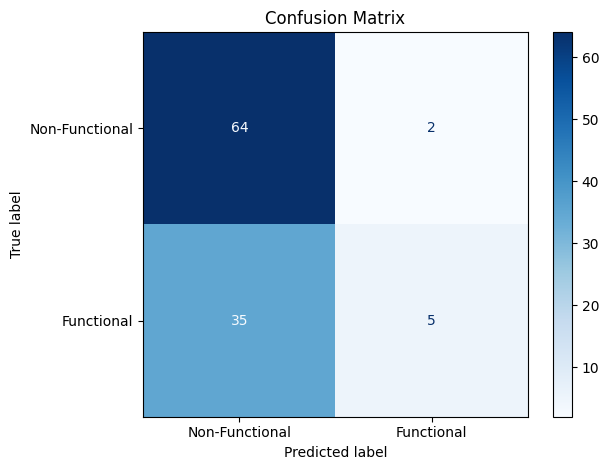

True Negatives  (TN): 64
False Positives (FP): 2
False Negatives (FN): 35
True Positives  (TP): 5


In [7]:
# Cell 7: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Functional', 'Functional'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

In [8]:
# Cell 8: Classification Report
print(classification_report(y_test, y_pred,
      target_names=['Non-Functional', 'Functional']))

                precision    recall  f1-score   support

Non-Functional       0.65      0.97      0.78        66
    Functional       0.71      0.12      0.21        40

      accuracy                           0.65       106
     macro avg       0.68      0.55      0.49       106
  weighted avg       0.67      0.65      0.56       106



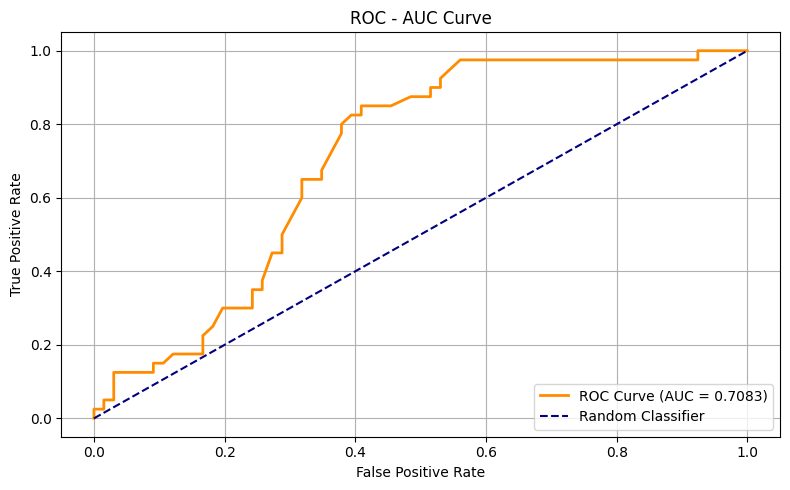

ROC-AUC Score: 0.7083


In [9]:
# Cell 9: ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC - AUC Curve")
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.savefig('roc_auc_curve.png')
plt.show()

print(f"ROC-AUC Score: {auc_score:.4f}")

In [10]:
# Cell 10: Threshold Tuning
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds_to_try = [0.3, 0.4, 0.5, 0.6, 0.7]
print(f"{'Threshold':<12} {'Precision':<12} {'Recall':<12} {'F1':<10}")
print("-" * 46)

for t in thresholds_to_try:
    y_pred_t = (y_prob >= t).astype(int)
    p = precision_score(y_test, y_pred_t, zero_division=0)
    r = recall_score(y_test, y_pred_t, zero_division=0)
    f = f1_score(y_test, y_pred_t, zero_division=0)
    print(f"{t:<12} {p:<12.4f} {r:<12.4f} {f:<10.4f}")

Threshold    Precision    Recall       F1        
----------------------------------------------
0.3          0.5139       0.9250       0.6607    
0.4          0.4865       0.4500       0.4675    
0.5          0.7143       0.1250       0.2128    
0.6          0.0000       0.0000       0.0000    
0.7          0.0000       0.0000       0.0000    


In [11]:
# Cell 11: Download saved plots
from google.colab import files
files.download('sigmoid_curve.png')
files.download('confusion_matrix.png')
files.download('roc_auc_curve.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>